# Supplementary Figure 4S NIA — independent replication in NIA muscle stem cells
Muscle stem cells from an independent laboratory (Shi et al., Aging Cell 2025; Hi-C GSE293131, RNA-seq GSE293130), young
(2–4 mo) / old (20–24 mo) / geriatric (27–32 mo), male, analysed like the Zhao data (`muscle_analysis.ipynb`) for young
vs geriatric and young vs old. Self-contained: computes the results (→ `data/nia/`), draws panels a–f
(→ `figures/fig4S_NIA_*.svg`) and assembles the page `Figure4S_NIA` (SVG in `../../illustrator-figures/`, SVG/PDF/PNG
in `figures/`). The analysis helpers, panel functions and page helpers are copies of those in the `muscle_*` notebooks,
so this notebook runs on its own. Runs in ~3 min.

In [1]:
import copy
import io
import json
import pickle
import sys
import xml.etree.ElementTree as ET

import cairosvg
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory
from PIL import Image

sys.path.insert(0, "..")                                # shared modules
import coloc_stats                                      # contact counting, per-state hypergeometric test + BH
import gsea                                             # preranked GSEA on the DESeq2 Wald statistic
import locus_null                                       # locus-matched permutation test

NIA = "/data/land/3d-inter-paper-data/muscle-sc-nia"
LAS = f"{NIA}/runs/pooled-v2/analysis"                 # G_all_<older>_vs_young graphs
RNA = f"{NIA}/rna"                                     # PyDESeq2 results (male samples; + = up in the older group)
EXPR = "data/nia/expression_by_age.csv"                 # per-age mean DESeq2-normalized counts (input, see README)
MM10_BINS = "/data/land/3d-inter-paper-data/cd8-hu/annot/mm10_250kb/mm10_250kb_bins_annotated.csv"   # node id = row
OUT = "data/nia"
FIG = "figures"
FILT = "20.0"
SIG = 0.05
PATHWAYS = json.load(open("../../metadata/mm10_hallmark_and_custom_pathways.json"))   # 60 Hallmark + custom (mouse)
CONTRASTS = [("geriatric", "Young (2–4 mo) vs Geriatric (27–32 mo)"), ("old", "Young (2–4 mo) vs Old (20–24 mo)")]
YOUNG = "#2c7fb8"                                      # main Figure 4 palette
OLD = "#d7301f"
GREY = "#BFBFBF"
BOTH = "#7b3294"
IFN = {"Interferon alpha response (H)": "IFN-α", "Interferon gamma response (H)": "IFN-γ"}   # labelled in e, f
bins = pd.read_csv(MM10_BINS)
graphs = {older: pickle.load(open(f"{LAS}/G_all_{older}_vs_young_filt_{FILT}.pkl", "rb")) for older, _ in CONTRASTS}

## Pathway colocalization (panels a, b, e, f)
Per contrast: per-state hypergeometric colocalization with fold enrichment vs each state's genome-wide share (BH over
the 60 sets; shared `../coloc_stats.py`), as for the Zhao data. Writes `data/nia/pathway_enrichment_young_vs_<older>.csv`.

In [2]:
def enrichment_table(G, A, B):
    """Per pathway: state-specific contact counts, shares, hypergeometric p / BH FDR, and fold vs genome share."""
    states = [A, B]
    bg = coloc_stats.count_contacts(G, "protein_coding_genes_with_tss")
    M = sum(bg.get(s, 0) for s in states) + bg.get("Shared", 0)
    rows = []
    for name, genes in PATHWAYS.items():
        row = coloc_stats.count_contacts(G, "protein_coding_genes_with_tss", genes)
        N = sum(row.get(s, 0) for s in states) + row.get("Shared", 0)
        rec = {"pathway": name, "n_pathway_contacts": N}
        for s in states:
            k = row.get(s, 0)
            rec[f"n_{s}"] = k
            rec[f"pct_{s}"] = 100 * k / N if N else np.nan
            rec[f"pval_{s}"] = coloc_stats.hypergeom_enrichment_pval(k, M, bg.get(s, 0), N) if N else np.nan
        rows.append(rec)
    res = pd.DataFrame(rows)
    for s in states:
        res[f"fdr_{s}"] = coloc_stats.bh(res[f"pval_{s}"])
        res[f"fold_{s}"] = res[f"pct_{s}"] / (100 * bg.get(s, 0) / M)
    return res

In [3]:
enrich = {}
for older, _ in CONTRASTS:
    enrich[older] = enrichment_table(graphs[older], "young", older)
    enrich[older].to_csv(f"{OUT}/pathway_enrichment_young_vs_{older}.csv", index=False)
    e = enrich[older]
    print(f"young vs {older}: FDR < 0.05 young {(e.fdr_young < SIG).sum()} / {older} {(e[f'fdr_{older}'] < SIG).sum()}")

young vs geriatric: FDR < 0.05 young 6 / geriatric 11


young vs old: FDR < 0.05 young 8 / old 8


## Pathway expression (GSEA) (panels e, f)
Preranked GSEA on the PyDESeq2 Wald statistic (shared `../gsea.py`). Writes `data/nia/gsea_young_vs_<older>.csv`.

In [4]:
gsea_res = {}
for older, _ in CONTRASTS:
    de = pd.read_csv(f"{RNA}/de_young_vs_{older}.csv", index_col=0)
    gsea_res[older] = gsea.prerank(gsea.deseq_rank(de), PATHWAYS)
    gsea_res[older].to_csv(f"{OUT}/gsea_young_vs_{older}.csv", index=False)
    print(f"young vs {older}: GSEA FDR < 0.05 {(gsea_res[older]['FDR q-val'] < SIG).sum()}")

2026-10-21 01:58:45,966 [WARNING] Duplicated values found in preranked stats: 12.88% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


2026-10-21 01:58:52,071 [WARNING] Duplicated values found in preranked stats: 12.30% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


young vs geriatric: GSEA FDR < 0.05 29


young vs old: GSEA FDR < 0.05 20


## Locus-matched permutation test (panels c, d)
As for the Zhao data (shared `../locus_null.py`, 10,000 draws, seed = 1000 + pathway position); expression strata from
the per-age mean DESeq2-normalized counts. Writes `data/nia/locus_matched_young_vs_<older>.csv`.

In [5]:
expr = pd.read_csv(EXPR, index_col=0)
locus = {}
for older, _ in CONTRASTS:
    expr_by_state = {s: expr[s] for s in ("young", older)}
    locus_null.prepare(graphs[older], bins, ("young", older), expr_by_state, gene_col="protein_coding_genes_with_tss")
    locus[older] = locus_null.test_family(PATHWAYS)
    locus[older].to_csv(f"{OUT}/locus_matched_young_vs_{older}.csv", index=False)
    n_locus = {s: int((locus[older][f"locus_p_{s}"] < 0.05).sum()) for s in ("young", older)}
    print(f"young vs {older}: locus p < 0.05 {n_locus}")

young vs geriatric: locus p < 0.05 {'young': 0, 'geriatric': 2}


young vs old: locus p < 0.05 {'young': 4, 'old': 3}


## Panels
Same encodings as the Zhao panels (`muscle_figures.ipynb`): young vs geriatric left column, young vs old right.

In [6]:
def light(c, f=0.55):
    """Opaque tint of a colour (mixed toward white), so Illustrator sees a flat fill."""
    return tuple(1 - f * (1 - x) for x in to_rgb(c))


def colocalization_panel(older, title, name):
    """Diverging fold enrichment of age-specific contacts for sets with FDR < 0.05 in either state."""
    f = enrich[older].set_index("pathway")
    fy, fo, qy, qo = f.fold_young, f[f"fold_{older}"], f.fdr_young, f[f"fdr_{older}"]
    order = sorted(f.index[(qy < SIG) | (qo < SIG)], key=lambda s: (fo[s] - 1) - (fy[s] - 1))
    half = np.ceil((max(fy[order].max(), fo[order].max()) - 1) * 4) / 4
    ticks = np.arange(0, half + 1e-6, 0.5)
    h = 0.4 * len(order) + 2.2
    fig, ax = plt.subplots(figsize=(8, h))
    for i, s in enumerate(order):
        ax.barh(i, max(0, fo[s] - 1), left=1, height=0.72, color=OLD if qo[s] < SIG else GREY, zorder=3)
        ax.barh(i, -max(0, fy[s] - 1), left=1, height=0.72, color=YOUNG if qy[s] < SIG else GREY, zorder=3)
        if qo[s] < SIG and fo[s] > 1:
            ax.text(fo[s] + 0.02, i, "*", va="center", color=OLD, fontsize=17)
        if qy[s] < SIG and fy[s] > 1:
            ax.text((2 - fy[s]) - 0.02, i, "*", va="center", ha="right", color=YOUNG, fontsize=17)
    ax.axvline(1, color="k", lw=0.8)
    ax.set_xlim(1 - half, 1 + half)
    ax.set_xticks(np.concatenate([1 - ticks[::-1], 1 + ticks[1:]]),
                  [f"{1 + t:.2f}".rstrip("0").rstrip(".") for t in np.concatenate([ticks[::-1], ticks[1:]])], fontsize=15)
    ax.set_yticks(range(len(order)), order, fontsize=17)
    ax.set_title(title, fontsize=17)
    ax.set_xlabel("Fold enrichment of\nage-specific contacts", fontsize=17)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    fig.legend(handles=[Patch(color=YOUNG, label="Young-specific"), Patch(color=OLD, label="Old-specific"),
                        mlines.Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")],
               loc="lower center", ncol=3, frameon=True, edgecolor="black", fontsize=15,
               # centred under the plot area (x in axes units), at the bottom of the figure (y in figure units)
               bbox_to_anchor=(0.5, 0), bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
    plt.tight_layout(rect=(0, 0.75 / h, 1, 1))                     # reserve ~0.75 in under the axis for the legend
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()


def panel_concordance(older, title, name):
    """x = GSEA NES, y = log2(old fold / young fold); colour = per-state hypergeometric FDR < 0.05."""
    f = enrich[older].set_index("pathway")
    g = gsea_res[older].set_index("Term")
    common = [p for p in f.index if p in g.index]
    x = g.loc[common, "NES"].astype(float).values
    with np.errstate(divide="ignore", invalid="ignore"):
        y = np.log2((f.loc[common, f"fold_{older}"] / f.loc[common, "fold_young"]).astype(float).values)
    o, yg = (f.loc[common, f"fdr_{older}"] < SIG).values, (f.loc[common, "fdr_young"] < SIG).values
    cat = np.where(o & yg, "both", np.where(o, "old", np.where(yg, "young", "ns")))
    colors = {"old": OLD, "young": YOUNG, "both": BOTH, "ns": GREY}
    names = {"old": "Old-specific (FDR < 0.05)", "young": "Young-specific (FDR < 0.05)", "both": "Both (FDR < 0.05)",
             "ns": "Not significant"}
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    for k in ["ns", "young", "both", "old"]:
        m = cat == k
        if m.any():
            ax.scatter(x[m], y[m], s=28 if k == "ns" else 40, color=colors[k], edgecolor="none",
                       zorder=2 if k == "ns" else 3, label=names[k])
    # interferon-alpha / -gamma outlined; the higher point labelled above, the other below, so labels never overlap
    pts = sorted(((p, common.index(p)) for p in IFN if p in common), key=lambda t: y[t[1]], reverse=True)
    for rank, (p, i) in enumerate(pts):
        ax.scatter(x[i], y[i], s=70, color=colors[cat[i]], edgecolor="black", linewidth=0.6, zorder=4)
        ax.annotate(IFN[p], (x[i], y[i]), fontsize=17, ha="right", va="bottom" if rank == 0 else "top",
                    xytext=(-6, 6 if rank == 0 else -6), textcoords="offset points")
    ax.set_xlabel("Expression, old vs young (GSEA NES)", fontsize=17)
    ax.set_ylabel("Colocalization\nlog$_2$(old fold / young fold)", fontsize=17)
    ax.set_title(title, fontsize=17)
    ax.tick_params(labelsize=15)
    ax.legend(loc="lower left", fontsize=15, frameon=True, edgecolor="black", title="Colocalization enrichment",
              title_fontsize=15)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()


def panel_locus(d, a, b, title, ca, cb, la, lb, name):
    """Mirrored -log10 nominal p bars (state a left, state b right); dark p < 0.05, light p <= 0.1."""
    keep = d[(d[f"locus_p_{a}"] <= 0.1) | (d[f"locus_p_{b}"] <= 0.1)]
    right = keep[f"locus_p_{b}"] <= keep[f"locus_p_{a}"]
    r = pd.concat([keep[~right].sort_values(f"locus_p_{a}"),                      # state-a block at the bottom
                   keep[right].sort_values(f"locus_p_{b}", ascending=False)])     # state-b block on top
    h = 0.4 * max(len(r), 3) + 2.2
    fig, ax = plt.subplots(figsize=(8, h))
    for i, (_, x) in enumerate(r.iterrows()):
        for p, side, col in ((x[f"locus_p_{a}"], -1, ca), (x[f"locus_p_{b}"], 1, cb)):
            if p <= 0.1:
                ax.barh(i, side * -np.log10(p), height=0.72, color=col if p < 0.05 else light(col), zorder=3)
    for s in (-1, 1):
        ax.axvline(s * -np.log10(0.05), color="black", lw=0.7, ls="--", zorder=2)
    ax.axvline(0, color="black", lw=0.8, zorder=4)
    lim = max(2.0, np.ceil((-np.log10(r[[f"locus_p_{a}", f"locus_p_{b}"]].min().min()) + 0.3) * 2) / 2)
    ticks = np.arange(0, lim + 0.01, 1)                              # whole-number ticks stay legible
    tick_pos = np.r_[-ticks[:0:-1], ticks]                            # mirrored: state a to the left of 0
    ax.set_xticks(tick_pos, [f"{abs(t):g}" for t in tick_pos], fontsize=15)
    ax.set_xlim(-lim, lim)
    ax.set_yticks(range(len(r)), r.set, fontsize=17)
    ax.set_ylim(-0.6, len(r) - 0.4)
    ax.set_xlabel("−log10 nominal p\n(locus-matched permutation)", fontsize=17)
    ax.set_title(title, fontsize=17)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.legend(handles=[Patch(color=cb, label=f"{lb}, p < 0.05"), Patch(color=light(cb), label=f"{lb}, p ≤ 0.1"),
                        Patch(color=ca, label=f"{la}, p < 0.05"), Patch(color=light(ca), label=f"{la}, p ≤ 0.1")],
               loc="lower center", ncol=2, frameon=True, edgecolor="black", fontsize=14,
               # centred on the plot area (x in axes units), at the bottom of the figure (y in figure units)
               bbox_to_anchor=(0.5, 0), bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
    plt.tight_layout(rect=(0, 0.95 / h, 1, 1))                     # reserve ~0.95 in under the axis for the legend
    plt.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()

### Supplementary Figure 4S NIA, panels a, b — Colocalized pathways (young vs geriatric | young vs old)

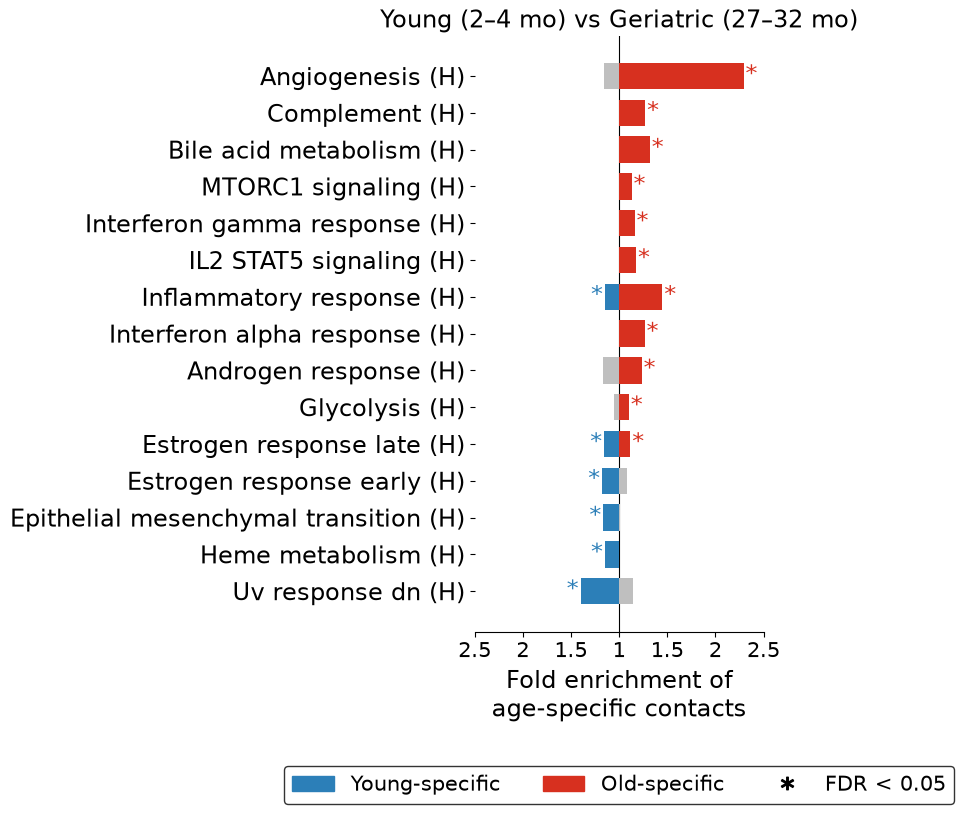

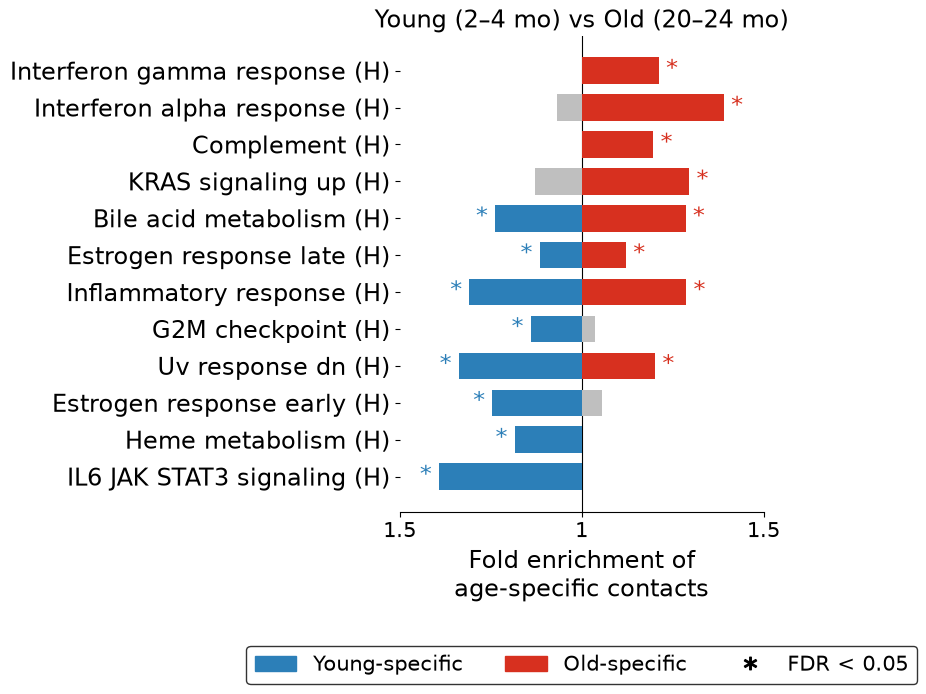

In [7]:
for (older, title), letter in zip(CONTRASTS, "ab"):
    colocalization_panel(older, title, f"fig4S_NIA_{letter}_colocalization_young_vs_{older}")

### Supplementary Figure 4S NIA, panels c, d — Locus-matched test (young vs geriatric | young vs old)

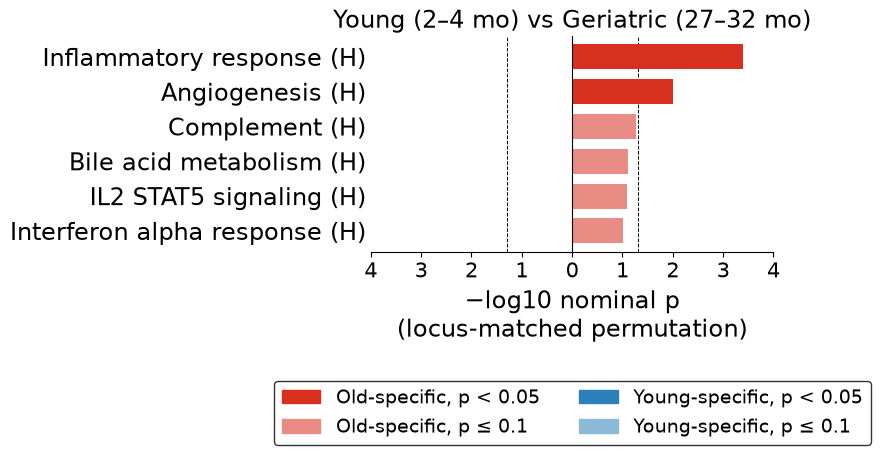

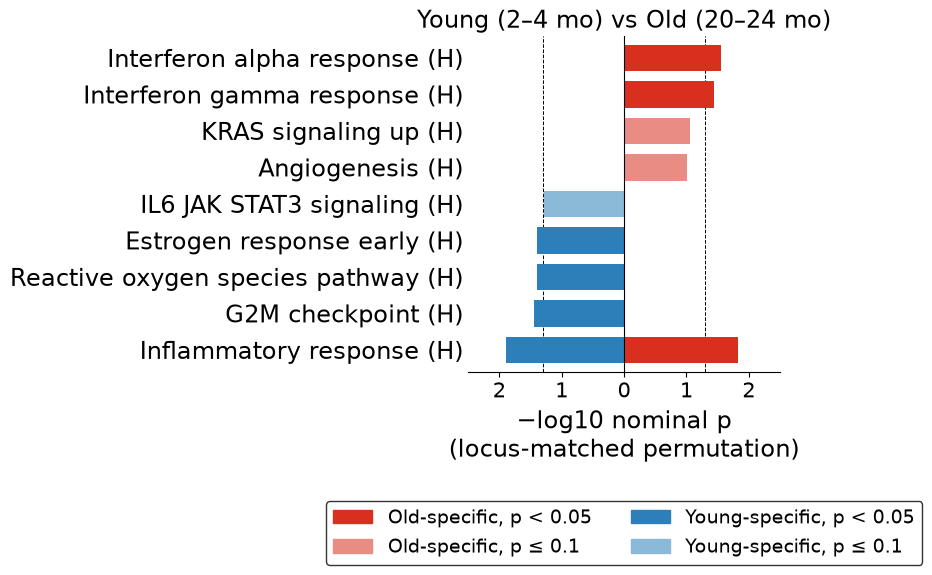

In [8]:
for (older, title), letter in zip(CONTRASTS, "cd"):
    panel_locus(locus[older], "young", older, title, YOUNG, OLD, "Young-specific", "Old-specific",
                f"fig4S_NIA_{letter}_locus_matched_young_vs_{older}")

### Supplementary Figure 4S NIA, panels e, f — Colocalization vs expression (young vs geriatric | young vs old)

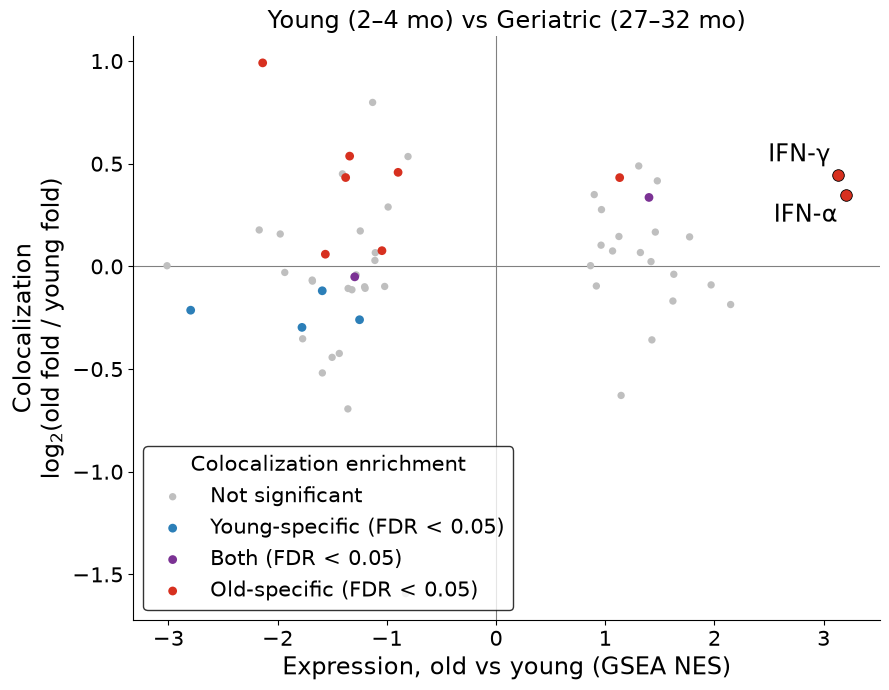

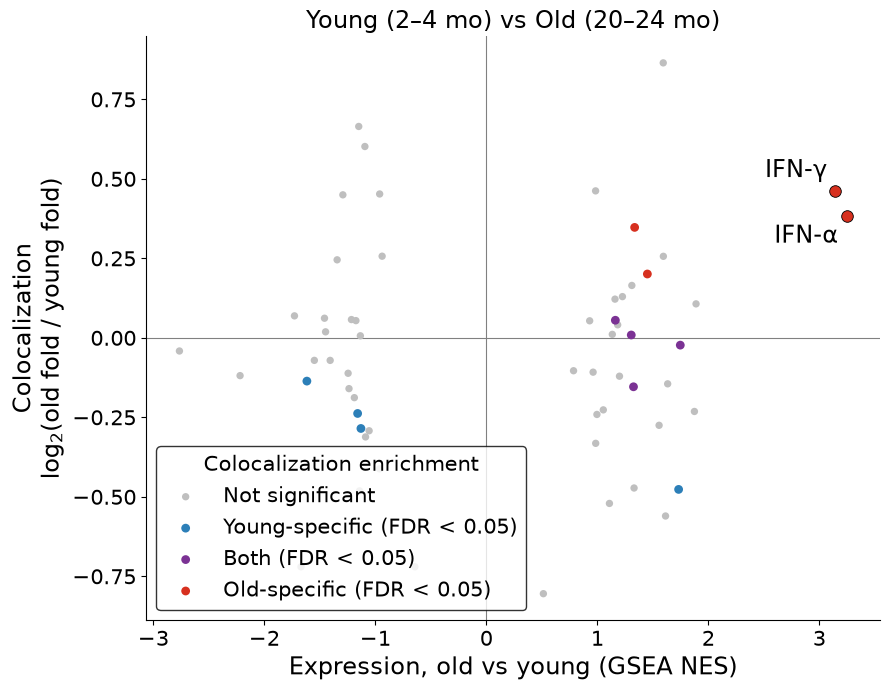

In [9]:
for (older, title), letter in zip(CONTRASTS, "ef"):
    panel_concordance(older, title, f"fig4S_NIA_{letter}_concordance_young_vs_{older}")

## Page — Supplementary Figure 4S NIA
Two columns (young vs geriatric | young vs old), three rows (a, b colocalization; c, d locus-matched; e, f
concordance); both panels of a row share one scale and are top-aligned; cropped tight.

In [10]:
PAGES = "../../illustrator-figures"
SVG_NS = "http://www.w3.org/2000/svg"
for prefix, uri in [("", SVG_NS), ("xlink", "http://www.w3.org/1999/xlink"), ("rdf", "http://www.w3.org/1999/02/22-rdf-syntax-ns#"),
                    ("cc", "http://creativecommons.org/ns#"), ("dc", "http://purl.org/dc/elements/1.1/")]:
    ET.register_namespace(prefix, uri)
PAGE_W, PAGE_H = 595.276, 841.89                       # A4 (pt) layout frame; cropped afterwards
CONTENT_X, CONTENT_W, GAP_X, GAP_Y, PAD = 28, 543, 18, 18, 4


def load(name):
    """Root element of a panel SVG in figures/."""
    return ET.parse(f"{FIG}/{name}.svg").getroot()


def new_page():
    """Blank A4 page with a white background."""
    page = ET.Element(f"{{{SVG_NS}}}svg", width=f"{PAGE_W}pt", height=f"{PAGE_H}pt", viewBox=f"0 0 {PAGE_W} {PAGE_H}")
    ET.SubElement(page, f"{{{SVG_NS}}}rect", id="background", x="0", y="0", width=f"{PAGE_W}", height=f"{PAGE_H}",
                  fill="#ffffff")
    return page


def nest(page, root, x, y, scale):
    """Place a panel SVG on the page at (x, y), scaled. Returns its bottom."""
    vb = [float(v) for v in root.get("viewBox").split()]
    child = ET.SubElement(page, f"{{{SVG_NS}}}svg", x=f"{x}", y=f"{y}", width=f"{vb[2] * scale}", height=f"{vb[3] * scale}",
                          viewBox=" ".join(f"{v}" for v in vb), preserveAspectRatio="xMinYMin meet", overflow="hidden")
    for el in root:
        child.append(copy.deepcopy(el))
    return y + vb[3] * scale


def letter(page, text, x, y):
    """Panel letter (Arial 12, lowercase + period)."""
    t = ET.SubElement(page, f"{{{SVG_NS}}}text", x=f"{x}", y=f"{y}",
                      style="font-family: Arial, ArialMT, sans-serif; font-size: 12px; fill: #000000")
    t.text = f"{text}."


def pair_row(page, letters, names, y):
    """Two panels side by side at one shared scale, top-aligned, spanning the content width. Returns the row bottom."""
    roots = [load(n) for n in names]
    widths = [float(r.get("viewBox").split()[2]) for r in roots]
    scale = (CONTENT_W - GAP_X) / sum(widths)
    x, bottom = CONTENT_X, y
    for lt, root, w in zip(letters, roots, widths):
        bottom = max(bottom, nest(page, root, x, y, scale))
        letter(page, lt, x - (11 if x == CONTENT_X else 4), y + 8)
        x += w * scale + GAP_X
    return bottom


def write(page, name):
    """Crop to the drawn content (+ PAD); save the SVG to illustrator-figures and SVG/PDF/PNG to figures/."""
    png = cairosvg.svg2png(bytestring=ET.tostring(page), scale=4)
    ink = np.asarray(Image.open(io.BytesIO(png)).convert("L")) < 250
    px = ink.shape[1] / PAGE_W
    rows = np.where(ink.any(axis=1))[0]
    cols = np.where(ink.any(axis=0))[0]
    x0, x1 = max(cols[0] / px - PAD, 0), min((cols[-1] + 1) / px + PAD, PAGE_W)
    y0, y1 = max(rows[0] / px - PAD, 0), min((rows[-1] + 1) / px + PAD, PAGE_H)
    page.set("viewBox", f"{x0:.2f} {y0:.2f} {x1 - x0:.2f} {y1 - y0:.2f}")
    page.set("width", f"{x1 - x0:.2f}pt")
    page.set("height", f"{y1 - y0:.2f}pt")
    page.find(f"{{{SVG_NS}}}rect[@id='background']").attrib.update(x=f"{x0:.2f}", y=f"{y0:.2f}", width=f"{x1 - x0:.2f}",
                                                                    height=f"{y1 - y0:.2f}")
    for path in (f"{PAGES}/{name}.svg", f"{FIG}/{name}.svg"):
        ET.ElementTree(page).write(path, xml_declaration=True, encoding="utf-8")
    cairosvg.svg2pdf(url=f"{FIG}/{name}.svg", write_to=f"{FIG}/{name}.pdf")
    cairosvg.svg2png(url=f"{FIG}/{name}.svg", write_to=f"{FIG}/{name}.png", scale=2)
    print(f"{name}: {x1 - x0:.0f} x {y1 - y0:.0f} pt")

In [11]:
page = new_page()
y = 17
for letters, kind in ((("a", "b"), "colocalization"), (("c", "d"), "locus_matched"), (("e", "f"), "concordance")):
    names = [f"fig4S_NIA_{lt}_{kind}_young_vs_{older}" for lt, (older, _) in zip(letters, CONTRASTS)]
    y = pair_row(page, letters, names, y) + GAP_Y
write(page, "Figure4S_NIA")

Figure4S_NIA: 559 x 641 pt
